# How-To: MTBF & MTTR Estimation (Repairable Systems)

| | |
|---|---|
| **Previous** | [How-To: MTBF Estimation](howto_MTBF_estimation.ipynb) |
| **Next** | [How-To: Critical Components](howto_critical_components.ipynb) |

In the previous notebook every component was **non-repairable** — once it
failed the system stayed down forever. In practice, failed components are
**repaired**. This introduces two new metrics alongside MTTF:

| Metric | Meaning |
|--------|---------|
| **MTTF** | Mean Time To Failure — average UP duration |
| **MTTR** | Mean Time To Repair — average DOWN duration |
| **MTBF** | Mean Time Between Failures — full cycle: **MTTF + MTTR** |

```

## Repairable system timeline

## ──────────────────────────────────────────────────────────

## UP    xxxxxxxxxxxxxxxxxx          xxxxxxxxxxxxxxxx          xx...
## DOWN                     xxxxxxxx                  xxxxxxxx
##      |<----- MTTF ----->|<-MTTR->|<---- MTTF ---->|<-MTTR->|
##      |<-------- MTBF ----------->|<--------- MTBF -------->|

##

## Non-repairable (for comparison)

## ──────────────────────────────────────────────────────────

## UP   xxxxxxxxxxxxxxxxxxxx
## DOWN                      xxxxxxxxxxxxxxxxxxxxxxxxxx... forever
##      |<----- MTTF ------>|  (no repair, system dead)

## ```

In [28]:
from pandapower.pf.no_numba import marker

import pandaict as pi
from pandaict.reliability.reliability import estimate_mtbf_mttr_for_conn
from demo_networks import simple_net
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

---
## Example 1 — First Repairable Network

The simplest repairable system: two nodes in series, perfect links.
Each node now has **MTTR = 24 h** (one day to repair).

```

## [Alice] --- (NodeA) ----- (NodeB) --- [Bob]
                    \         /
##                 MTBF = 8784 h,
##                 MTTR = 24 h

## ~~~~ links are perfect (never fail) ~~~~

##
```

Since the two nodes are in series the system fails whenever **either** node
fails. Analytically:

$$
\text{MTTF}_{\text{sys}}
  = \frac{1}{\lambda_A + \lambda_B}
  = \frac{8\,760}{2}
  = 4\,380 \;\text{h}
$$



In [43]:
net, appA, appB = simple_net(mtbf_h_n=8784, mttr_h_n=24, mtbf_h_l=0, mttr_h_l=0)
conn = pi.create_ict_connection(net, name='Alice->Bob', from_app=appA, to_app=appB, protocol="TCP")

result = estimate_mtbf_mttr_for_conn(net, [conn], N=int(1e6), depth=100)

print(f"MTTF = {result['mttf_h']:.1f} h   (time until system failure)")
print(f"MTTR = {result['mttr_h']:.1f} h   (time to restore the system)")
print(f"MTBF = {result['mtbf_h']:.1f} h   (full cycle = MTTF + MTTR)")

Running 100000000 (1000000 x 100) simulations in parallel...
MTTF = 4379.9 h   (time until system failure)
MTTR = 24.0 h   (time to restore the system)
MTBF = 4403.9 h   (full cycle = MTTF + MTTR)


**Interpretation**

| Metric | Analytical | Simulated | Note |
|--------|-----------|-----------|------|
| MTTF | 4 380 h | ≈ 4 380 h | Same formula as the non-repairable case |
| MTTR | 24 h | ≈ 24 h | Only one node breaks → one repair |
| MTBF | 4 404 h | ≈ 4 404 h | MTTF + MTTR |

Repair does **not** change *when* the system fails — it changes
*how fast it comes back*.

---
## Example 2 — Repairable vs. Non-Repairable

Side-by-side comparison on the **same topology**.

In [33]:
# Non-repairable (from notebook 1)
net_nr, appA_nr, appB_nr = simple_net(mtbf_h_n=8760, mtbf_h_l=0, mttr_h_n=0, mttr_h_l=0)
conn_nr = pi.create_ict_connection(net_nr, name="Alice->Bob (non-repairable)", from_app=appA_nr, to_app=appB_nr, protocol="TCP")
result_nr = estimate_mtbf_mttr_for_conn(net_nr, [conn_nr], N=int(1e6))

# Repairable (already computed above)
result_r = result

# ── build comparison table ──
rows = {
    "MTTF (h)": [f"{result_nr['mttf_h']:,.0f}",
                 f"{result_r['mttf_h']:,.0f}"],
    "MTTR (h)": ["∞  (non-repairable)",
                 f"{result_r['mttr_h']:,.1f}"],
    "MTBF (h)": [f"{result_nr['mtbf_h']:,.0f}",
                 f"{result_r['mtbf_h']:,.0f}"],
}
df_cmp = pd.DataFrame(rows, index=["Non-Repairable (MTTR = 0)",
                                    "Repairable  (MTTR = 24 h)"]).T
df_cmp

Running 1000000 simulations in parallel...


,Non-Repairable (MTTR = 0),Repairable (MTTR = 24 h)
MTTF (h),"4,378","4,369"
MTTR (h),∞ (non-repairable),24.0
MTBF (h),"4,378","4,393"


**Key observations**

* **MTTF is almost identical** — repair does not prevent failures.
* **MTTR** is finite for the repairable system, infinite for the
  non-repairable one (once it fails, it never recovers).
* For non-repairable systems the function returns `mttr_h = `$\infty$ and sets
  `mtbf_h = mttf_h` by convention.

---
## Example 3 — Effect of Repair Speed

How does the component repair time affect the system-level metrics?
We sweep MTTR from 2 h (emergency repair) to 168 h (one week).

Since changing the MTTR (while keeping the MTBF constant) would implicitely change the MTTF:
```{math}
\text{MTBF} = \text{MTTF} + \text{MTTR} \Rightarrow \text{MTTF} = \text{MTBF} - \text{MTTR}
```
We have to adjust the MTBF in order to keep the MTTF konstant.

In [44]:
mttr_values = [2, 8, 24, 48, 72, 168]
records = []
mttf = 8760

for mttr in mttr_values:
    mtbf = mttf + mttr
    net_i, appA_i, appB_i = simple_net(mtbf_h_n=mtbf, mttr_h_n=mttr, mtbf_h_l=0)
    conn_i = pi.create_ict_connection(net_i, name="", from_app=appA_i, to_app=appB_i, protocol="TCP")
    r = estimate_mtbf_mttr_for_conn(net_i, [conn_i], N=100_000)
    records.append(dict(mttr_input=mttr,
                        mttf_h=r["mttf_h"],
                        mttr_h=r["mttr_h"],
                        mtbf_h=r["mtbf_h"]))

df = pd.DataFrame(records)
df

Running 20000000 (100000 x 200) simulations in parallel...
Running 20000000 (100000 x 200) simulations in parallel...
Running 20000000 (100000 x 200) simulations in parallel...
Running 20000000 (100000 x 200) simulations in parallel...
Running 20000000 (100000 x 200) simulations in parallel...
Running 20000000 (100000 x 200) simulations in parallel...


,mttr_input,mttf_h,mttr_h,mtbf_h
0,2,4380.470983,2.000267,4382.471250
1,8,4379.237597,8.006248,4387.243845
2,24,4381.365257,24.033228,4405.398485
3,48,4380.048296,48.144329,4428.192625
4,72,4380.318995,72.282799,4452.601795
5,168,4379.519977,169.637479,4549.157456


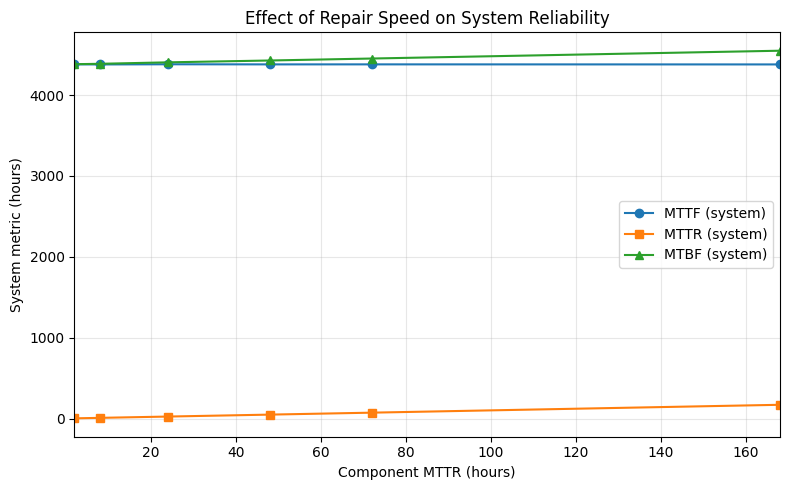

In [51]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(df["mttr_input"], df["mttf_h"], "o-", label="MTTF (system)")
ax.plot(df["mttr_input"], df["mttr_h"], "s-", label="MTTR (system)")
ax.plot(df["mttr_input"], df["mtbf_h"], "^-", label="MTBF (system)")
ax.set_xlabel("Component MTTR (hours)")
ax.set_ylabel("System metric (hours)")
ax.set_title("Effect of Repair Speed on System Reliability")
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xlim(df["mttr_input"].min(), df["mttr_input"].max())
plt.tight_layout()
plt.show()

**Observations**

* **MTTF is roughly constant** (≈ 4 380 h) — repair speed has no influence
  on *how often* the system fails.
* **MTTR grows linearly** with component repair time.
* **MTBF = MTTF + MTTR** increases accordingly.

> Faster repair does not prevent failures — it minimises downtime per
> failure.

---
## Example 4 — System Availability

**Availability** is the fraction of time the system is operational:

$$A = \frac{\text{MTTF}}{\text{MTBF}}
    = \frac{\text{MTTF}}{\text{MTTF} + \text{MTTR}}$$

Telecom SLAs are often expressed as *"number of nines"*
(e.g. 99.99 % → "four nines").

In [49]:
df["availability"] = df["mttf_h"] / df["mtbf_h"]
df["downtime_per_year_h"] = (1 - df["availability"]) * 8760
df["nines"] = -np.log10(1 - df["availability"])

display_cols = ["mttr_input", "availability", "downtime_per_year_h", "nines"]
df_avail = df[display_cols].copy()
df_avail.columns = ["Comp. MTTR (h)", "Availability",
                     "Downtime / year (h)", "Nines"]
df_avail["Availability"] = df_avail["Availability"].map("{:.4%}".format)
df_avail["Downtime / year (h)"] = df_avail["Downtime / year (h)"].map("{:.1f}".format)
df_avail["Nines"] = df_avail["Nines"].map("{:.2f}".format)
df_avail

,Comp. MTTR (h),Availability,Downtime / year (h),Nines
0,2,99.9544%,4.0,3.34
1,8,99.8175%,16.0,2.74
2,24,99.4545%,47.8,2.26
3,48,98.9128%,95.2,1.96
4,72,98.3766%,142.2,1.79
5,168,96.2710%,326.7,1.43


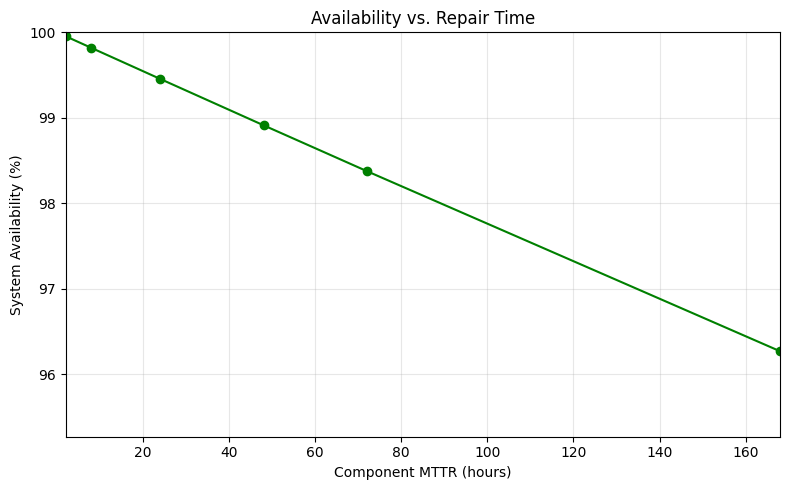

In [60]:
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(df["mttr_input"], df["availability"] * 100, "o-", color="green")
ax1.set_xlabel("Component MTTR (hours)")
ax1.set_ylabel("System Availability (%)")
ax1.set_ylim(
    max(90, df["availability"].min() * 100 - 1),
    min(100.0, df["availability"].max() * 100 + 0.5),
)
ax1.set_title("Availability vs. Repair Time")
ax1.grid(alpha=0.3)
ax1.set_xlim(df["mttr_input"].min(), df["mttr_input"].max())
plt.tight_layout()
plt.show()

With a 2-hour emergency repair the system exceeds 99.9 % availability.
A one-week repair cycle drops it to roughly 96 %.

> **Take-away:** Even modest improvements in repair speed can push a system
> into a higher availability tier.

---
## Example 5 — The `depth` Parameter

For repairable systems the Monte-Carlo engine simulates many consecutive
UP->DOWN->UP cycles per run.  The **`depth`** parameter controls how many
cycles are collected.

**Why does it matter?**
Every simulation starts with *all components UP* - the best possible state.
The very first MTTF sample is therefore slightly optimistic.  Subsequent
cycles start from more realistic partially-degraded states.
With `depth ≥ 100` (the default is 200) this initial warm-up bias is
diluted. Stochastically the mixing of those parameters leads to an optimized coverage of the (ergodic) state space. See also: <a class="reference internal" href="../reliability-Monte-Carlo.html">Technical Documentation: Reliability Monte-Carlo</a>

In [58]:
depths = [1, 2, 5, 10, 50, 100, 200, 500]
depth_records = []

for d in depths:
    r = estimate_mtbf_mttr_for_conn(net, [conn], N=50_000, depth=d)
    depth_records.append(dict(depth=d,
                              mttf_h=r["mttf_h"],
                              mttr_h=r["mttr_h"]))

df_d = pd.DataFrame(depth_records)
df_d

Running 50000 (50000 x 1) simulations in parallel...
Running 100000 (50000 x 2) simulations in parallel...
Running 250000 (50000 x 5) simulations in parallel...
Running 500000 (50000 x 10) simulations in parallel...
Running 2500000 (50000 x 50) simulations in parallel...
Running 5000000 (50000 x 100) simulations in parallel...
Running 10000000 (50000 x 200) simulations in parallel...
Running 25000000 (50000 x 500) simulations in parallel...


,depth,mttf_h,mttr_h
0,1,4402.086863,24.018316
1,2,4391.321921,24.128339
2,5,4378.905224,23.980858
3,10,4379.697601,24.022526
4,50,4383.358170,24.022673
5,100,4379.110274,24.037164
6,200,4380.932755,24.025438
7,500,4380.578222,24.038784


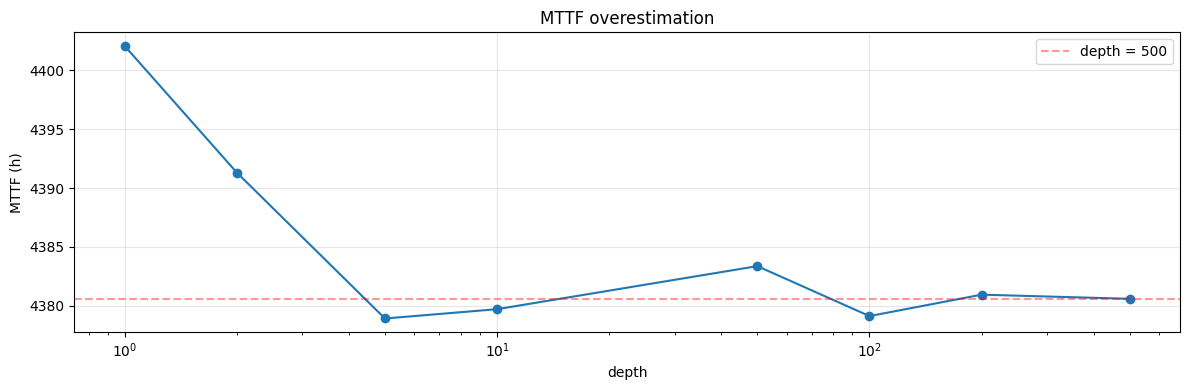

In [61]:
fig, ax1 = plt.subplots(figsize=(12, 4))

ax1.semilogx(df_d["depth"], df_d["mttf_h"], "o-")
ax1.axhline(df_d["mttf_h"].iloc[-1], ls="--", c="red", alpha=.4,
            label=f"depth = {depths[-1]}")
ax1.set_xlabel("depth")
ax1.set_ylabel("MTTF (h)")
ax1.set_title("MTTF overestimation")
ax1.legend()
ax1.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

For this simple two-node network the estimates are stable even at low
`depth`.  For larger networks with redundant paths the warm-up bias can be
more pronounced.

> **Recommendation:** Leave `depth` at its default (200).  The
> computational overhead is linear and almost always negligible.

---
## Summary

| Concept | Symbol | Meaning |
|---------|--------|---------|
| Mean Time To Failure | MTTF | Average UP duration |
| Mean Time To Repair | MTTR | Average DOWN duration |
| Mean Time Between Failures | MTBF | MTTF + MTTR (full cycle) |
| Availability | *A* | MTTF / MTBF |

**Key take-aways**

1. Make components repairable by setting `mttr_h > 0`.
2. Repair does **not** change MTTF — it only controls how fast the system
   recovers.
3. Faster repair -> higher availability.
4. Use `depth ≥ 100` for unbiased estimates (default is 200).

**Next:** [How-To: Critical Components](howto_critical_components.ipynb) —
find out *which* components cause the most system failures.